In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

import Minimal_Model_1D as M



In [14]:
NUM = 51


### ALL lineas pass through pt (omega, mu) = (4, 3)

##L1
OMEGAL1 = np.linspace(1, 6, NUM)
MUL1 = OMEGAL1/2 + 1

##L2
OMEGAL2 = np.linspace(22/5, 22/7, NUM)
MUL2 = -2*OMEGAL2  + 11

##L3
OMEGAH = np.linspace(2, 6, NUM)
MUH = 3*np.ones(NUM)

##L4
OMEGAV = 4*np.ones(NUM)
MUV = np.linspace(2, 6, NUM)

##SUB1
OMEGAS1 = np.linspace(1,6.2,NUM)
MUS1 = OMEGAS1/2*np.ones(NUM)

##SUB1
OMEGAS2 = np.linspace(1,6.2,NUM)
MUS2 = 3*OMEGAS2/2

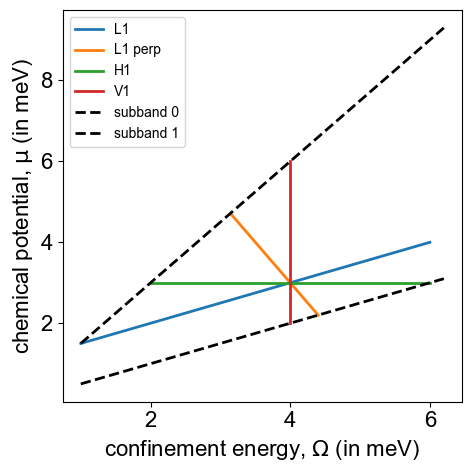

In [15]:

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=16)

# Create figure with a specific size
f = plt.figure(figsize=(5, 5))

# Data for the plot
OMEGA = np.linspace(1, 5, 21)
MU = np.linspace(1, 5, 21)

# Plot lines with different labels
plt.plot(OMEGAL1,  MUL1, lw=2, label='L1')
plt.plot(OMEGAL2, MUL2, lw=2, label='L1 perp')
plt.plot(OMEGAH, MUH, lw=2, label='H1')
plt.plot(OMEGAV, MUV, lw=2, label='V1')
plt.plot(OMEGAS1, MUS1, lw=2, linestyle='dashed', color='black', label=f'subband 0')
plt.plot(OMEGAS2, MUS2, lw=2, linestyle='dashed', color='black', label=f'subband 1')
# Set axis limits
#plt.ylim(ymax=4, ymin=0)
#plt.xlim(xmin=0)

# Add labels
plt.xlabel(r'confinement energy, $\mathrm{\Omega}$ (in meV)')
plt.ylabel(r'chemical potential, $\mathrm{\mu}$ (in meV)')



# Dynamically scale legend font size based on figure size
fig_width, fig_height = f.get_size_inches()
font_size = min(fig_width, fig_height) * 2  # Proportional font size

# Add the legend with the scaled font size
plt.legend(loc='upper left', prop={'size': font_size}, fontsize=10)

# Show plot
plt.tight_layout()
plt.show()


In [16]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT_L = 20
ALPHAT_C = 400 
K = 8 

In [17]:
### DATA FOR L1 linear AND cubic

Ep_li_1d = np.empty((NUM,K))

for i in range(NUM):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAL1[i], ALPHAT_L, DELTA, MEFF_SC, MEFF_SM, MUL1[i], MUL1[i])
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("linear_E_L1_compact_pt_4_3_omega_from_{}_to_{}_num_{}.npy".format(OMEGAL1[0], OMEGAL1[-1], NUM), Ep_li_1d)


Ep_cu_1d = np.empty((NUM,K))

for i in range(NUM):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAL1[i], ALPHAT_C, DELTA, MEFF_SC, MEFF_SM, MUL1[i], MUL1[i])
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)


np.save("cubic_E_L1_compact_pt_4_3_omega_from_{}_to_{}_num_{}.npy".format(OMEGAL1[0], OMEGAL1[-1], NUM), Ep_cu_1d)

0
5
10
15
20
25
30
35
40
45
50
0
5
10
15
20
25
30
35
40
45
50


In [18]:
### DATA FOR L2



Ep_li_1d = np.empty((NUM,K))

for i in range(NUM):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAL2[i], ALPHAT_L, DELTA, MEFF_SC, MEFF_SM, MUL2[i], MUL2[i])
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("linear_E_L2_compact_pt_4_3_omega_from_{}_to_{}_num_{}.npy".format(round(OMEGAL2[0],2), round(OMEGAL2[-1],2), NUM), Ep_li_1d)


Ep_cu_1d = np.empty((NUM,K))

for i in range(NUM):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAL2[i], ALPHAT_C, DELTA, MEFF_SC, MEFF_SM, MUL2[i], MUL2[i])
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)


np.save("cubic_E_L2_compact_pt_4_3_omega_from_{}_to_{}_num_{}.npy".format(round(OMEGAL2[0],2), round(OMEGAL2[-1],2), NUM), Ep_cu_1d)

0
5
10
15
20
25
30
35
40
45
50
0
5
10
15
20
25
30
35
40
45
50


In [19]:
### DATA FOR H



Ep_li_1d = np.empty((NUM,K))

for i in range(NUM):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAH[i], ALPHAT_L, DELTA, MEFF_SC, MEFF_SM, MUH[i], MUH[i])
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("linear_E_H_compact_omega_pt_4_3_from_{}_to_{}_num_{}.npy".format(OMEGAH[0], OMEGAH[-1], NUM), Ep_li_1d)


Ep_cu_1d = np.empty((NUM,K))

for i in range(NUM):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAH[i], ALPHAT_C, DELTA, MEFF_SC, MEFF_SM, MUH[i], MUH[i])
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)


np.save("cubic_E_H_compact_omega_pt_4_3_from_{}_to_{}_num_{}.npy".format(OMEGAH[0], OMEGAH[-1], NUM), Ep_cu_1d)

0
5
10
15
20
25
30
35
40
45
50
0
5
10
15
20
25
30
35
40
45
50


In [20]:
### DATA FOR V



Ep_li_1d = np.empty((NUM,K))

for i in range(NUM):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAV[i], ALPHAT_L, DELTA, MEFF_SC, MEFF_SM, MUV[i], MUV[i])
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li_1d[i,:] = Eli
    
    if i%5==0:
        print(i)

np.save("linear_E_V_compact_omega_pt_4_3_from_{}_to_{}_num_{}.npy".format(OMEGAV[0], OMEGAV[-1], NUM), Ep_li_1d)


Ep_cu_1d = np.empty((NUM,K))

for i in range(NUM):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAV[i], ALPHAT_C, DELTA, MEFF_SC, MEFF_SM, MUV[i], MUV[i])
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)


np.save("cubic_E_V_compact_omega_pt_4_3_from_{}_to_{}_num_{}.npy".format(OMEGAV[0], OMEGAV[-1], NUM), Ep_cu_1d)

0
5
10
15
20
25
30
35
40
45
50
0
5
10
15
20
25
30
35
40
45
50


In [21]:
Eli_L1 = np.load("linear_E_L1_compact_pt_4_3_omega_from_1.0_to_6.0_num_51.npy")
Eli_L2 = np.load("linear_E_L2_compact_pt_4_3_omega_from_4.4_to_3.14_num_51.npy")
Eli_H = np.load("linear_E_H_compact_omega_pt_4_3_from_2.0_to_6.0_num_51.npy")
Eli_V = np.load("linear_E_V_compact_omega_pt_4_3_from_4.0_to_4.0_num_51.npy")

Ecu_L1 = np.load("cubic_E_L1_compact_pt_4_3_omega_from_1.0_to_6.0_num_51.npy")
Ecu_L2 = np.load("cubic_E_L2_compact_pt_4_3_omega_from_4.4_to_3.14_num_51.npy")
Ecu_H = np.load("cubic_E_H_compact_omega_pt_4_3_from_2.0_to_6.0_num_51.npy")
Ecu_V = np.load("cubic_E_V_compact_omega_pt_4_3_from_4.0_to_4.0_num_51.npy")


DELTA = 0.165
K=8
NUM = 51


### ALL lineas pass through pt (omega, mu) = (4, 3)
##L1
OMEGAL1 = np.linspace(1, 6, NUM)
MUL1 = OMEGAL1/2 + 1

##L2
OMEGAL2 = np.linspace(22/5, 22/7, NUM)
MUL2 = -2*OMEGAL2  + 11

##L3
OMEGAH = np.linspace(2, 6, NUM)
MUH = 3*np.ones(NUM)

##L4
OMEGAV = 4*np.ones(NUM)
MUV = np.linspace(2, 6, NUM)

##SUB1
OMEGAS1 = np.linspace(1,6.2,NUM)
MUS1 = OMEGAS1/2*np.ones(NUM)

##SUB1
OMEGAS2 = np.linspace(1,6.2,NUM)
MUS2 = 3*OMEGAS2/2

In [22]:
def dist(omega, mu, sign_array):

    ### returns an array which gives distance from point 3,2.3 fro given omega , mu array 

    A = np.sqrt((omega - 4)**2 + (mu - 3)**2)

    return  A*sign_array

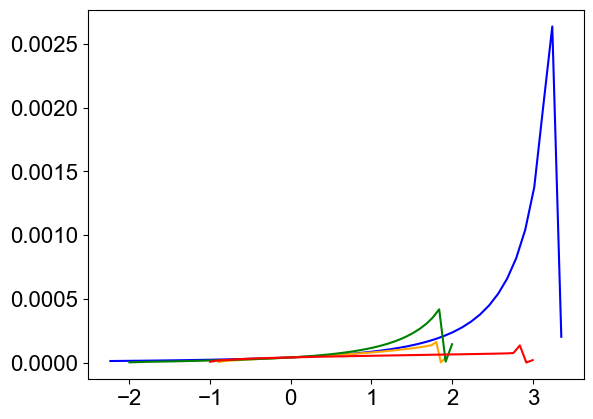

In [23]:
DELTA = 0.165
K=8
NUM = 51


### ALL lineas pass through pt (omega, mu) = (4, 3)

##L1

S1 = np.where(OMEGAL1>=4, -1, +1)
RL1 = dist(OMEGAL1, MUL1,S1)

plt.plot(RL1, Eli_L1[:,K//2+1]-Eli_L1[:,K//2], color='blue')

##L2
S2 = np.where(OMEGAL2>=4, -1, +1)
RL2 = dist(OMEGAL2, MUL2,S2)

plt.plot(RL2, Eli_L2[:,K//2+1]-Eli_L2[:,K//2], color='orange')

##L3
S3 = np.where(OMEGAH>=4, -1, +1)
RL3 = dist(OMEGAH, MUH, S3)

plt.plot(RL3, Eli_H[:,K//2+1]-Eli_H[:,K//2], color='green')

##L4
S4 = np.where(MUV>=3, +1, -1)
RL4 = dist(OMEGAV, MUV, S4)

plt.plot(RL4, Eli_V[:,K//2+1]-Eli_V[:,K//2], color='red')


(2.5e-05, 0.000125)

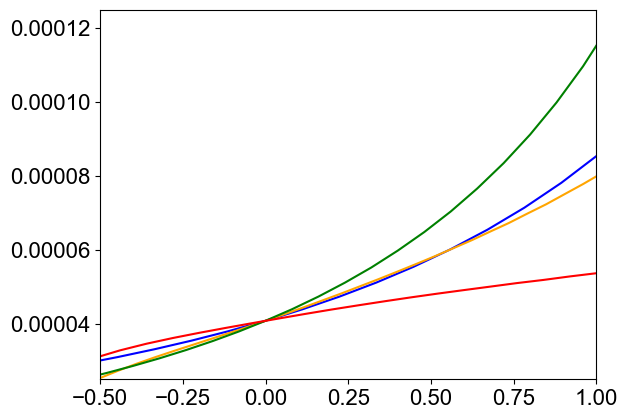

In [26]:
DELTA = 0.165
K=8
NUM = 51


### ALL lineas pass through pt (omega, mu) = (4, 3)

##L1

S1 = np.where(OMEGAL1>=4, -1, +1)
RL1 = dist(OMEGAL1, MUL1,S1)

plt.plot(RL1, Eli_L1[:,K//2+1]-Eli_L1[:,K//2], color='blue')

##L2
S2 = np.where(OMEGAL2>=4, -1, +1)
RL2 = dist(OMEGAL2, MUL2,S2)

plt.plot(RL2, Eli_L2[:,K//2+1]-Eli_L2[:,K//2], color='orange')

##L3
S3 = np.where(OMEGAH>=4, -1, +1)
RL3 = dist(OMEGAH, MUH, S3)

plt.plot(RL3, Eli_H[:,K//2+1]-Eli_H[:,K//2], color='green')

##L4
S4 = np.where(MUV>=3, +1, -1)
RL4 = dist(OMEGAV, MUV, S4)

plt.plot(RL4, Eli_V[:,K//2+1]-Eli_V[:,K//2], color='red')


plt.xlim(xmax=1, xmin=-0.5)
plt.ylim(ymax=0.000125, ymin=0.000025)

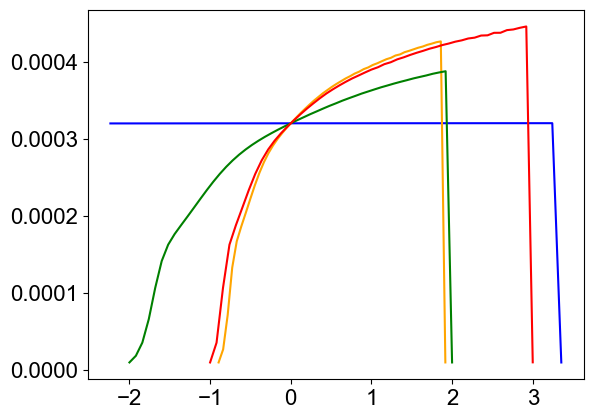

In [27]:
DELTA = 0.165
K=8
NUM = 51


### ALL lineas pass through pt (omega, mu) = (3, 2.3)

##L1


plt.plot(RL1, Ecu_L1[:,K//2+1]-Ecu_L1[:,K//2], color='blue')

##L2


plt.plot(RL2, Ecu_L2[:,K//2+1]-Ecu_L2[:,K//2], color='orange')

##L3


plt.plot(RL3, Ecu_H[:,K//2+1]-Ecu_H[:,K//2], color='green')

##L4


plt.plot(RL4, Ecu_V[:,K//2+1]-Ecu_V[:,K//2], color='red')


#plt.xlim(xmax=1, xmin=-0.5)
#plt.ylim(ymax=0.0004, ymin=0.00004)

(0.0002, 0.0004)

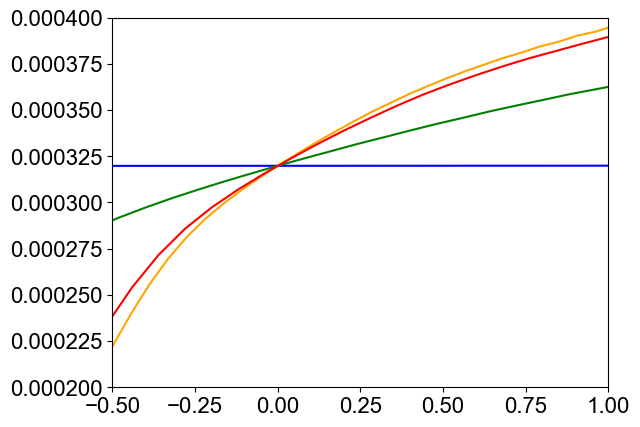

In [30]:
DELTA = 0.165
K=8
NUM = 51


### ALL lineas pass through pt (omega, mu) = (3, 2.3)

##L1

plt.plot(RL1, Ecu_L1[:,K//2+1]-Ecu_L1[:,K//2], color='blue')

##L2


plt.plot(RL2, Ecu_L2[:,K//2+1]-Ecu_L2[:,K//2], color='orange')

##L3


plt.plot(RL3, Ecu_H[:,K//2+1]-Ecu_H[:,K//2], color='green')

##L4

plt.plot(RL4, Ecu_V[:,K//2+1]-Ecu_V[:,K//2], color='red')


plt.xlim(xmax=1, xmin=-0.5)
plt.ylim(ymax=0.0004, ymin=0.00020)

In [103]:
### calculating slope for Es wrt r along blue(L1) and orange(L2) line

##L1
OMEGAL1 = np.linspace(1, 5, NUM)
MUL1 = OMEGAL1 / 2 + 0.8
S1 = np.where(OMEGAL1>=3, -1, +1)
RL1 = dist(OMEGAL1, MUL1,S1)
Eli_split_L1 = Eli_L1[:,K//2+1]-Eli_L1[:,K//2]

SLOPE_LI_L1 = np.empty(NUM)

for i in range(NUM-1):

    SLOPE_LI_L1[i] = (Eli_split_L1[i+1] - Eli_split_L1[i])/(RL1[i+1]- RL1[i])/DELTA


print(SLOPE_LI_L1)

### l2
OMEGAL2 = np.linspace(16.6/7, 16.6/5, NUM)
MUL2 = -2*OMEGAL2  + 5*3/2 + 0.8
S2 = np.where(OMEGAL2>=3, -1, +1)
RL2 = dist(OMEGAL2, MUL2,S2)
Eli_split_L2 = Eli_L2[:,K//2+1]-Eli_L2[:,K//2]

SLOPE_LI_L2 = np.empty(NUM)

for i in range(NUM-1):

    SLOPE_LI_L2[i] = (Eli_split_L2[i+1] - Eli_split_L2[i])/(RL2[i+1]- RL2[i])/DELTA


print(SLOPE_LI_L2)

[5.78200274e-02 3.22115242e-02 2.18887306e-02 1.59525193e-02
 1.20484800e-02 9.31832690e-03 7.34045620e-03 5.87185200e-03
 4.75998843e-03 3.90428056e-03 3.23619024e-03 2.70786162e-03
 2.28520936e-03 1.94353800e-03 1.66468218e-03 1.43509581e-03
 1.24455035e-03 1.08523313e-03 9.51112988e-04 8.37488044e-04
 7.40659036e-04 6.57690634e-04 5.86235083e-04 5.24400578e-04
 4.70652055e-04 4.23735754e-04 3.82621354e-04 3.46457243e-04
 3.14535667e-04 2.86265394e-04 2.61150117e-04 2.38771289e-04
 2.18774388e-04 2.00857878e-04 1.84764275e-04 1.70272881e-04
 1.57193853e-04 1.45363332e-04 1.34639419e-04 1.24898857e-04
 1.16034255e-04 1.07951784e-04 1.00569234e-04 9.38143924e-05
 8.76236632e-05 8.19409056e-05 7.67164440e-05 7.19062249e-05
 6.74710961e-05 6.33761893e-05 1.98940514e-05]
[ 8.76004041e-03  4.04351837e-03 -4.45110808e-02  2.73705905e-03
  2.22843834e-03  1.95509144e-03  1.66481748e-03  1.61729228e-03
  1.50566117e-03  1.34504878e-03  1.33791095e-03  1.23765530e-03
  1.15157657e-03  1.135555

In [104]:
### calculating slope for Es wrt r along blue(L1) and orange(L2) line

##L1
OMEGAL1 = np.linspace(1, 5, NUM)
MUL1 = OMEGAL1 / 2 + 0.8
S1 = np.where(OMEGAL1>=3, -1, +1)
RL1 = dist(OMEGAL1, MUL1,S1)
Ecu_split_L1 = Ecu_L1[:,K//2+1]-Ecu_L1[:,K//2]

SLOPE_CU_L1 = np.empty(NUM)

for i in range(NUM-1):

    SLOPE_CU_L1[i] = (Ecu_split_L1[i+1] - Ecu_split_L1[i])/(RL1[i+1]- RL1[i])/DELTA


print(SLOPE_CU_L1)

### l2
OMEGAL2 = np.linspace(16.6/7, 16.6/5, NUM)
MUL2 = -2*OMEGAL2  + 5*3/2 + 0.8
S2 = np.where(OMEGAL2>=3, -1, +1)
RL2 = dist(OMEGAL2, MUL2,S2)
Ecu_split_L2 = Ecu_L2[:,K//2+1]-Ecu_L2[:,K//2]

SLOPE_CU_L2 = np.empty(NUM)

for i in range(NUM-1):

    SLOPE_CU_L2[i] = (Ecu_split_L2[i+1] - Ecu_split_L2[i])/(RL2[i+1]- RL2[i])/DELTA


print(SLOPE_CU_L2)

[1.05534444e-07 1.09495998e-07 1.33345240e-07 1.60269471e-07
 1.85843201e-07 2.08904563e-07 2.29305678e-07 2.47225026e-07
 2.62933433e-07 2.76708682e-07 2.88806335e-07 2.99451056e-07
 3.08836721e-07 3.17128907e-07 3.24468609e-07 3.30976023e-07
 3.36753764e-07 3.41889400e-07 3.46458098e-07 3.50524593e-07
 3.54144927e-07 3.57367186e-07 3.60233817e-07 3.62781285e-07
 3.65042044e-07 3.67043864e-07 3.68812088e-07 3.70368477e-07
 3.71732437e-07 3.72921360e-07 3.73950552e-07 3.74833815e-07
 3.75583460e-07 3.76210537e-07 3.76724895e-07 3.77135477e-07
 3.77450597e-07 3.77677281e-07 3.77822224e-07 3.77891544e-07
 3.77890622e-07 3.77824545e-07 3.77697671e-07 3.77514448e-07
 3.77278486e-07 3.76993352e-07 3.76662298e-07 3.76288216e-07
 3.75873873e-07 3.75421757e-07 2.97237297e-04]
[-5.62470321e-02  2.59731227e-04  3.64055306e-04  1.84660761e-04
  2.77269987e-04  3.61068015e-04  2.14366770e-04  3.14233458e-04
  3.46808675e-04  2.59269665e-04  3.54581443e-04  3.35200557e-04
  3.31631041e-04  3.812502

(-0.001, 0.004)

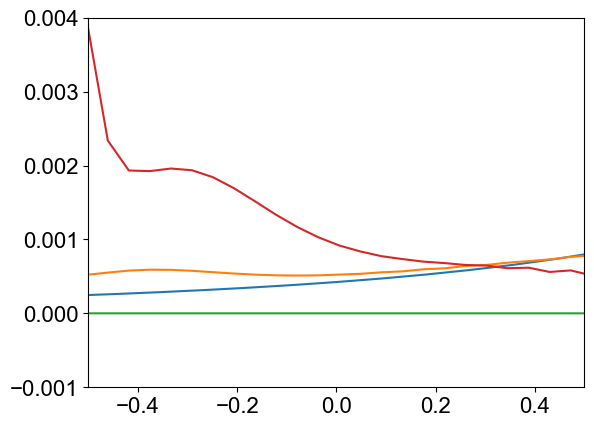

In [115]:
plt.plot(RL1, SLOPE_LI_L1)
plt.plot(RL2, SLOPE_LI_L2)
plt.plot(RL1, SLOPE_CU_L1)
plt.plot(RL2, SLOPE_CU_L2)
plt.xlim(xmin=-0.5, xmax=0.5)
plt.ylim(ymin=-0.001, ymax=0.004)